Name: Jess Choi  
Github Username: yulimjchoi  
USC ID: 9452440573 

## 1. Tree-Based Methods

Import packages

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import scatter_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score
from IPython.display import display
from xgboost import XGBClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

### (a) Download the APS Failure data

In [4]:
train = pd.read_csv('../data/aps_failure_training_set.csv', skiprows=20, na_values='na')
test = pd.read_csv('../data/aps_failure_test_set.csv', skiprows=20, na_values='na')
print('Train:', train.shape, 'Test:', test.shape)

Train: (60000, 171) Test: (16000, 171)


In [5]:
train.info()
test.info()
train.describe()
test.describe()

<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 171 entries, class to eg_000
dtypes: float64(169), int64(1), str(1)
memory usage: 78.4 MB
<class 'pandas.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Columns: 171 entries, class to eg_000
dtypes: float64(169), int64(1), str(1)
memory usage: 20.9 MB


,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
count,1.600000e+04,3637.000000,1.507400e+04,12019.000000,15310.000000,15310.000000,15811.000000,1.581100e+04,1.581100e+04,1.581100e+04,...,1.580800e+04,1.580800e+04,1.580800e+04,1.580800e+04,1.580800e+04,1.580800e+04,1.580800e+04,1.580800e+04,15238.000000,15238.000000
mean,6.799698e+04,0.772065,3.580393e+08,439.498794,6.428347,10.195950,120.858516,2.064204e+03,1.379236e+04,1.126276e+05,...,4.649135e+05,2.212010e+05,4.690886e+05,4.256696e+05,3.559239e+05,3.524014e+05,1.442759e+05,8.560355e+03,0.064969,0.242683
std,5.035350e+05,2.589224,7.966968e+08,1551.328109,118.186469,167.260463,6454.660300,8.925778e+04,2.358405e+05,1.025843e+06,...,1.255197e+06,5.828691e+05,1.267550e+06,1.259560e+06,1.199544e+06,1.628545e+06,5.368225e+05,5.329946e+04,3.374657,14.339059
min,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000
25%,9.280000e+02,0.000000,1.600000e+01,26.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,...,3.178000e+03,1.256000e+03,2.883500e+03,3.869500e+03,6.100000e+02,1.240000e+02,0.000000e+00,0.000000e+00,0.000000,0.000000
50%,3.098200e+04,0.000000,1.590000e+02,130.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,...,2.409860e+05,1.147800e+05,2.297080e+05,1.956510e+05,9.657000e+04,4.201300e+04,3.985000e+03,0.000000e+00,0.000000,0.000000
75%,4.947900e+04,0.000000,1.003500e+03,430.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,...,4.391320e+05,2.189510e+05,4.714860e+05,4.034105e+05,2.790355e+05,1.699100e+05,1.389310e+05,1.907000e+03,0.000000,0.000000
max,4.294967e+07,58.000000,2.130707e+09,87038.000000,11044.000000,14186.000000,736174.000000,1.047252e+07,1.914916e+07,7.305747e+07,...,5.382333e+07,2.207969e+07,4.859750e+07,5.604348e+07,4.215944e+07,4.747137e+07,1.718575e+07,4.570398e+06,340.000000,1720.000000


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

We can remove the features if missing values are too many and they are not important features for our analysis. Also, we can replace the missing values with mean or median values of that columns. In this homework, I will use median because many features contain extreme values, so the median is less affected than the mean. Also, I will use replacement instead of removing the features to avoid discarding potentially useful operational information.

In [6]:
X_train = train.drop(columns='class')
X_test = test.drop(columns='class')
train_medians = X_train.median()
X_train_imputed = X_train.fillna(train_medians)
X_test_imputed = X_test.fillna(X_test.median())

#### (ii) Calculate the coefficient of variation

In [7]:
cv = X_train_imputed.std(ddof=1) / X_train_imputed.mean()
cv.sort_values(ascending=False)

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
             ...    
bo_000      0.792383
bp_000      0.753392
bq_000      0.718534
br_000      0.689112
cd_000      0.000000
Length: 170, dtype: float64

#### (iii) Plot a correlation matrix

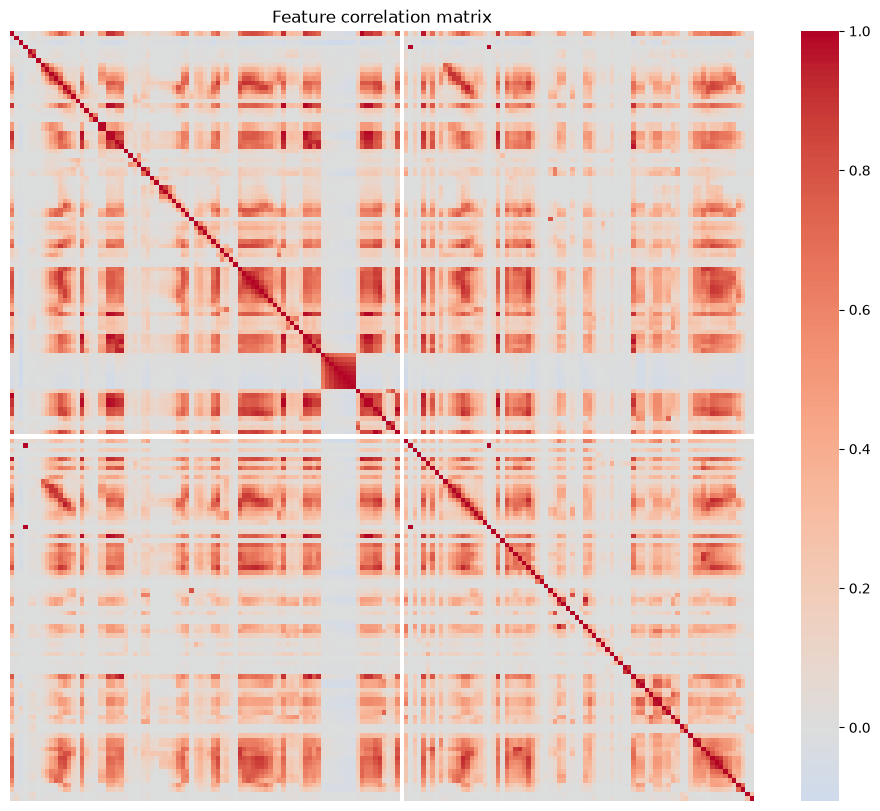

In [8]:
plt.figure(figsize=(12, 10))
sns.heatmap(X_train_imputed.corr(), cmap='coolwarm', center=0, xticklabels=False, yticklabels=False)
plt.title('Feature correlation matrix')
plt.show()

#### (iv) Make scatter plots and box plots

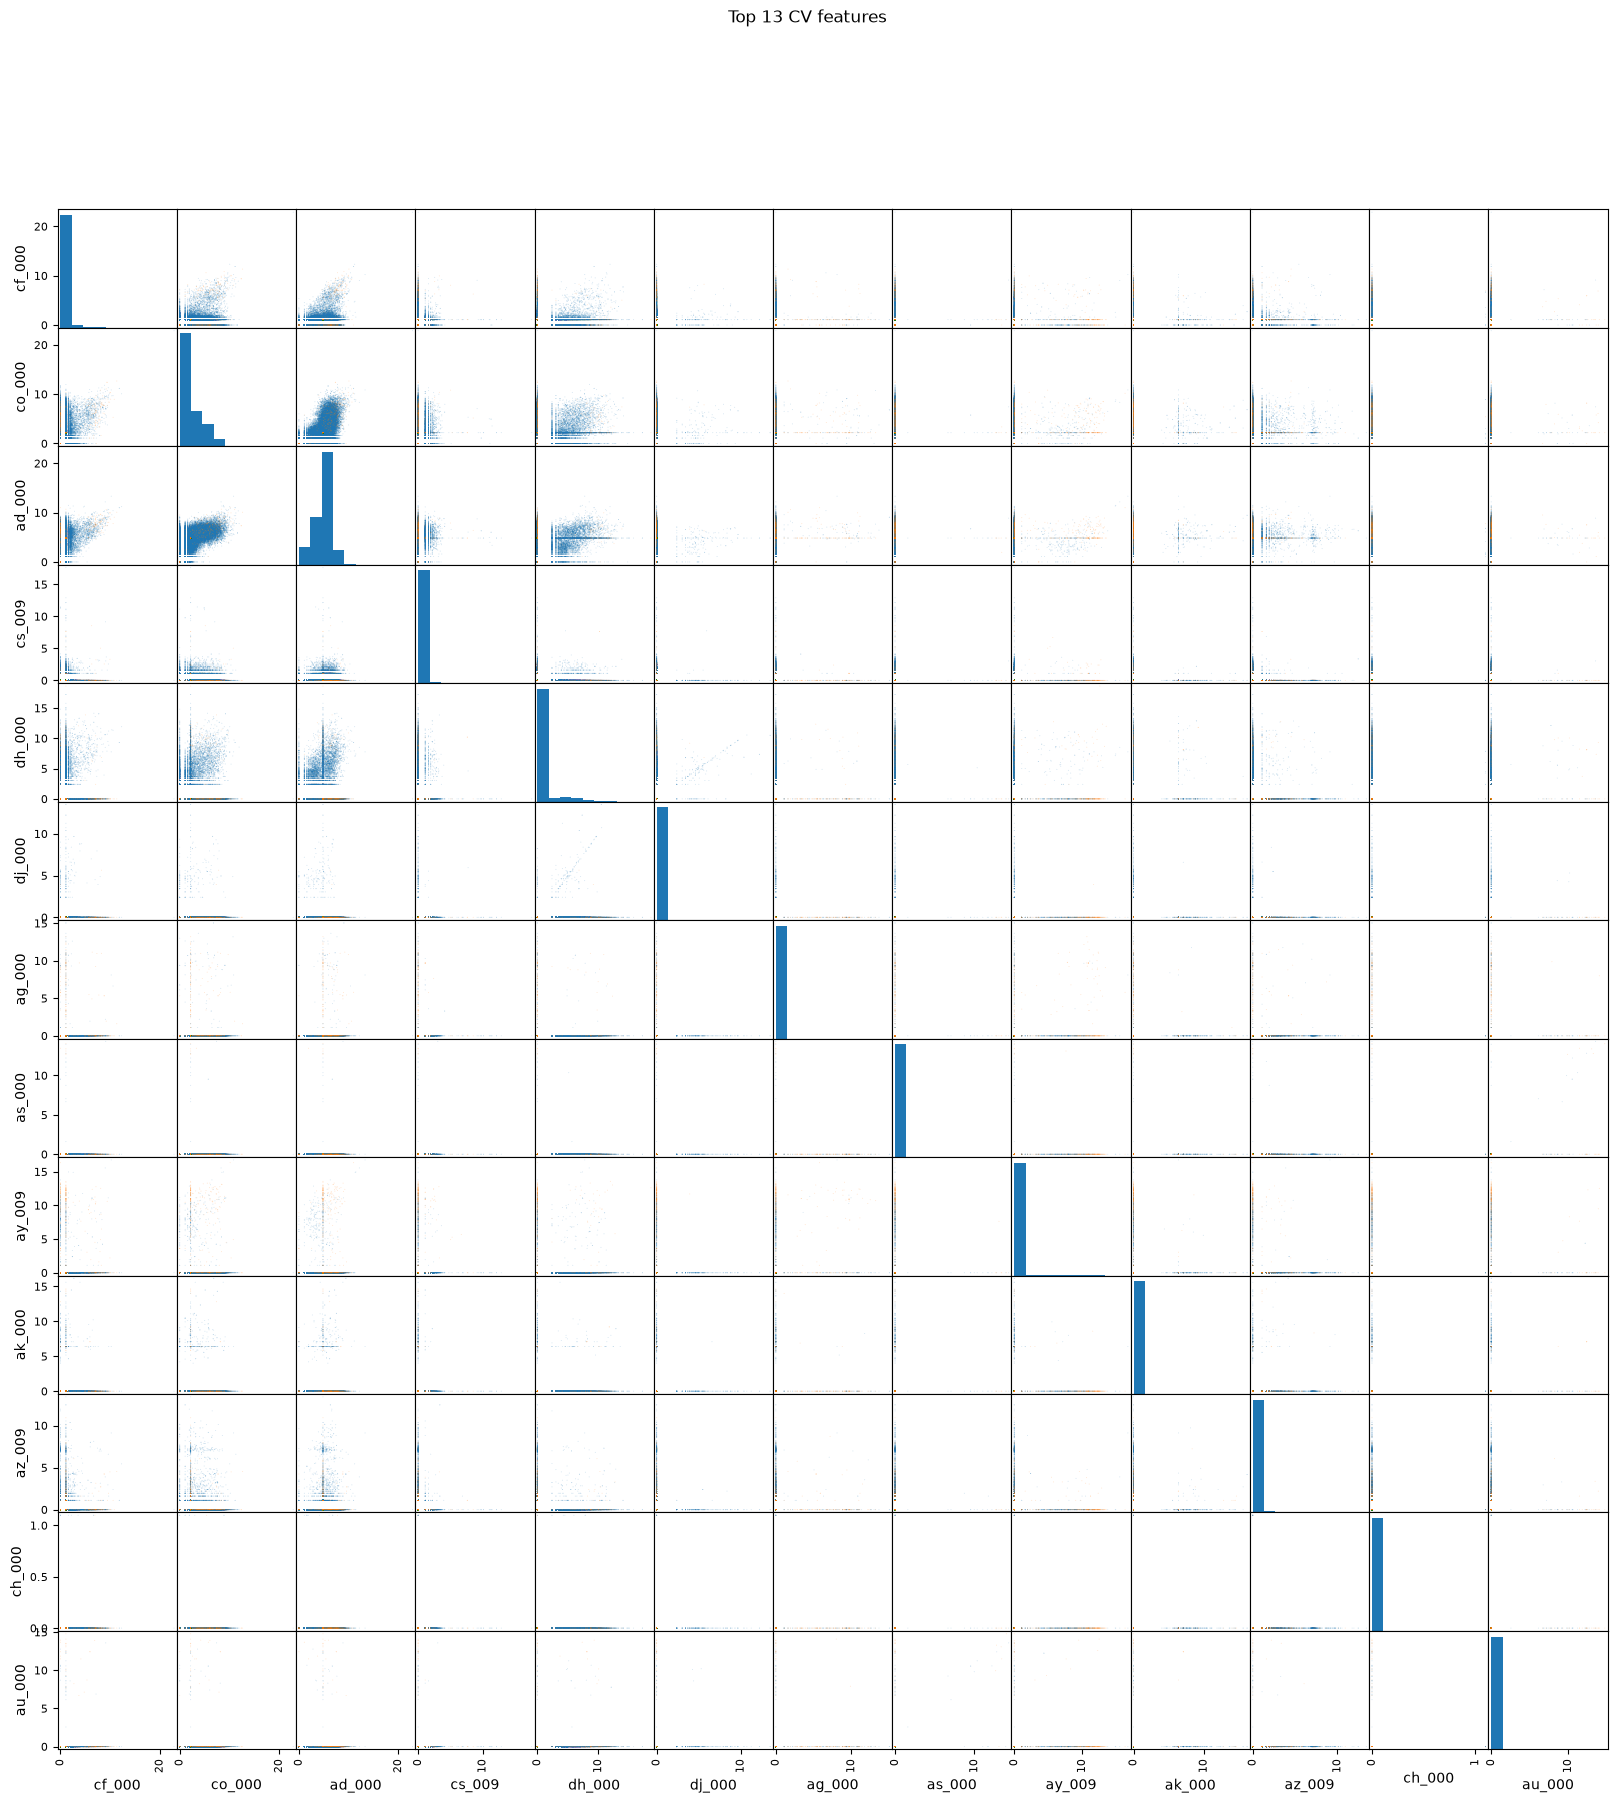

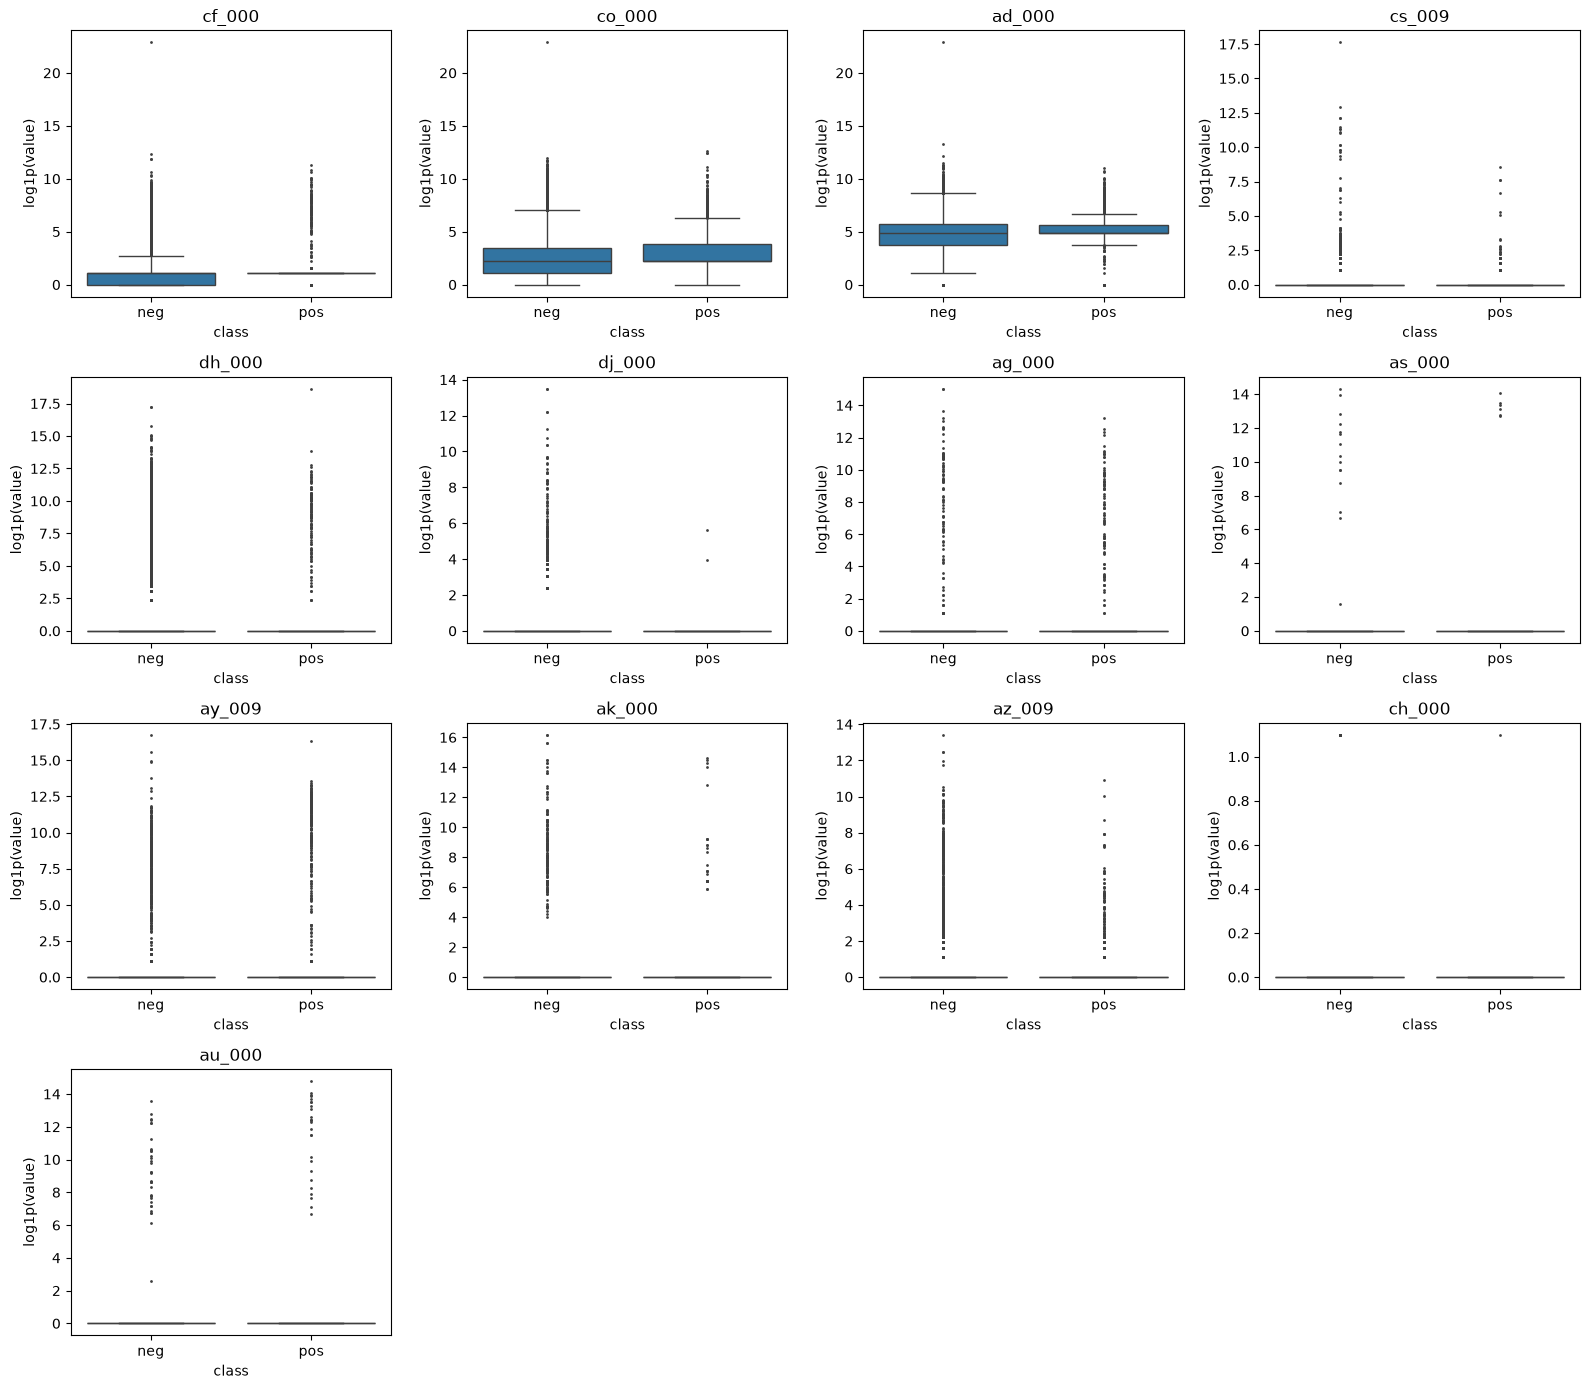

In [9]:
top_features = cv.nlargest(int(np.sqrt(len(cv)))).index.tolist()
order = train.sort_values('class').index
colors = train.loc[order, 'class'].map({'neg': 'tab:blue','pos': 'tab:orange'})
scatter_matrix(np.log1p(X_train_imputed.loc[order, top_features]), c=colors, alpha=0.2, s=2, figsize=(20, 20), diagonal='hist')
plt.suptitle('Top 13 CV features')
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(16, 14))
for ax, feature in zip(axes.flat, top_features):
    sns.boxplot(x=train['class'], y=np.log1p(X_train_imputed[feature]), ax=ax, fliersize=1)
    ax.set_title(feature)
    ax.set_ylabel('log1p(value)')
for ax in axes.flat[len(top_features):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

No, I cannot draw conclusions only by the scatter plots. The scatter plots show that many observations overlap or cluster near zero. Therefore, it is difficult to distinguish the two classes visually. Also, a high coefficient of variation indicates variability, but does not establish that a feature is useful for classification.

#### (v) Is this data set imbalanced?

In [10]:
counts = train['class'].value_counts()
counts

class
neg    59000
pos     1000
Name: count, dtype: int64

The training set it imbalanced.

### (c) Train a random forest

In [11]:
y_train = train['class'].eq('pos').astype(int)
y_test = test['class'].eq('pos').astype(int)

def report_rf(model):
    results, roc_tables = {}, {}

    for name, X, y in [('Train', X_train_imputed, y_train), ('Test', X_test_imputed, y_test)]:
        pred = model.predict(X)
        prob = model.predict_proba(X)[:, 1]
        error = 1 - accuracy_score(y, pred)
        auc = roc_auc_score(y, prob)
        fpr, tpr, thresholds = roc_curve(y, prob)

        results[f'{name} error'] = error
        results[f'{name} AUC'] = auc
        roc_tables[name] = pd.DataFrame({'threshold': thresholds, 'FPR': fpr, 'TPR': tpr})

        print(f'{name} confusion matrix (rows=true, columns=predicted):')
        print(confusion_matrix(y, pred))
        print(f'Misclassification: {error:.6f}; AUC: {auc:.4f}')
        print(f'{name} ROC coordinates:')
        display(roc_tables[name])

    results['OOB error'] = 1 - model.oob_score_
    print(f'OOB error: {results["OOB error"]:.6f}; 'f'test error: {results["Test error"]:.6f}')
    return results, roc_tables

rf_plain = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42, n_jobs=-1)
rf_plain.fit(X_train_imputed, y_train)
plain_results, plain_roc = report_rf(rf_plain)

Train confusion matrix (rows=true, columns=predicted):
[[59000     0]
 [    1   999]]
Misclassification: 0.000017; AUC: 1.0000
Train ROC coordinates:


,threshold,FPR,TPR
0,inf,0.000000,0.000
1,1.00,0.000000,0.030
2,0.99,0.000000,0.073
3,0.98,0.000000,0.117
4,0.97,0.000000,0.171
...,...,...,...
66,0.04,0.018831,1.000
67,0.03,0.023966,1.000
68,0.02,0.032729,1.000
69,0.01,0.061000,1.000


Test confusion matrix (rows=true, columns=predicted):
[[15610    15]
 [  106   269]]
Misclassification: 0.007563; AUC: 0.9928
Test ROC coordinates:


,threshold,FPR,TPR
0,inf,0.000000,0.000000
1,1.00,0.000000,0.008000
2,0.99,0.000000,0.021333
3,0.98,0.000000,0.029333
4,0.97,0.000000,0.048000
...,...,...,...
89,0.04,0.033984,0.976000
90,0.03,0.040896,0.976000
91,0.02,0.052864,0.976000
92,0.01,0.089856,0.992000


OOB error: 0.006117; test error: 0.007563


### (d) Research class imbalance in random forest

We can use the 'balanced_subsample' mode. It recalculates class weights inversely proportional to their frequencies in each tree's bootstrap sample.

In [12]:
rf_balanced = RandomForestClassifier(n_estimators=100, oob_score=True, class_weight='balanced_subsample', random_state=42, n_jobs=-1)
rf_balanced.fit(X_train_imputed, y_train)
balanced_results, balanced_roc = report_rf(rf_balanced)
pd.DataFrame({'Unbalanced RF': plain_results, 'Balanced RF': balanced_results})

Train confusion matrix (rows=true, columns=predicted):
[[59000     0]
 [    1   999]]
Misclassification: 0.000017; AUC: 1.0000
Train ROC coordinates:


,threshold,FPR,TPR
0,inf,0.000000,0.000
1,1.00,0.000000,0.016
2,0.99,0.000000,0.033
3,0.98,0.000000,0.064
4,0.97,0.000000,0.089
...,...,...,...
70,0.04,0.016712,1.000
71,0.03,0.022576,1.000
72,0.02,0.032136,1.000
73,0.01,0.062017,1.000


Test confusion matrix (rows=true, columns=predicted):
[[15608    17]
 [  158   217]]
Misclassification: 0.010938; AUC: 0.9892
Test ROC coordinates:


,threshold,FPR,TPR
0,inf,0.000000,0.000000
1,0.99,0.000000,0.002667
2,0.98,0.000000,0.005333
3,0.96,0.000000,0.021333
4,0.94,0.000000,0.053333
...,...,...,...
90,0.04,0.030720,0.968000
91,0.03,0.036480,0.973333
92,0.02,0.049984,0.981333
93,0.01,0.090944,0.986667


OOB error: 0.008033; test error: 0.010938


,Unbalanced RF,Balanced RF
Train error,0.000017,0.000017
Train AUC,1.000000,1.000000
Test error,0.007563,0.010938
Test AUC,0.992766,0.989158
OOB error,0.006117,0.008033


Compared with the result of 1(c), the test misclassification rate increased, the test AUC decreased, and the number of false negative increased. Therefore, this method did not improve performance.

### (e) XGBoost and Model Trees

In [13]:
def xgb_model():
    return XGBClassifier(booster='gbtree', objective='binary:logistic', n_estimators=100, 
                         reg_alpha=0, reg_lambda=0, random_state=42, n_jobs=1)

def report_xgb(model):
    results = {}

    for name, X, y in [('Train', X_train, y_train), ('Test', X_test_imputed, y_test)]:
        pred = model.predict(X)
        prob = model.predict_proba(X)[:, 1]
        fpr, tpr, thresholds = roc_curve(y, prob)

        results[f'{name} error'] = 1 - accuracy_score(y, pred)
        results[f'{name} AUC'] = roc_auc_score(y, prob)

        print(f'{name} confusion matrix (rows=true, columns=predicted):')
        print(confusion_matrix(y, pred))
        print(f'{name} AUC: {results[f"{name} AUC"]:.4f}')
        print(f'{name} ROC coordinates:')
        display(pd.DataFrame({'threshold': thresholds, 'FPR': fpr, 'TPR': tpr}))

    return results

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
plain_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', xgb_model())
])

xgb_plain_cv = GridSearchCV(plain_pipe, 
                            {'model__reg_alpha': [0.1, 1, 10]}, cv=cv5, scoring='accuracy', n_jobs=1)
xgb_plain_cv.fit(X_train, y_train)

plain_xgb_results = report_xgb(xgb_plain_cv.best_estimator_)
plain_xgb_results['CV error'] = 1 - xgb_plain_cv.best_score_

print('Best alpha:', xgb_plain_cv.best_params_['model__reg_alpha'])
print(f'CV error: {plain_xgb_results["CV error"]:.6f}')
print(f'Test error: {plain_xgb_results["Test error"]:.6f}')

Train confusion matrix (rows=true, columns=predicted):
[[59000     0]
 [    1   999]]
Train AUC: 1.0000
Train ROC coordinates:


,threshold,FPR,TPR
0,inf,0.000000,0.000
1,1.000000e+00,0.000000,0.047
2,9.999999e-01,0.000000,0.077
3,9.999998e-01,0.000000,0.090
4,9.999996e-01,0.000000,0.099
...,...,...,...
11973,9.173006e-18,0.999644,1.000
11974,7.716406e-18,0.999678,1.000
11975,6.458942e-18,0.999712,1.000
11976,6.153064e-18,0.999763,1.000


Test confusion matrix (rows=true, columns=predicted):
[[15600    25]
 [   90   285]]
Test AUC: 0.9876
Test ROC coordinates:


,threshold,FPR,TPR
0,inf,0.000000,0.000000
1,1.000000e+00,0.000064,0.026667
2,9.999999e-01,0.000064,0.045333
3,9.999998e-01,0.000064,0.053333
4,9.999996e-01,0.000064,0.072000
...,...,...,...
1384,1.369125e-10,0.998784,1.000000
1385,1.097159e-10,0.998912,1.000000
1386,8.734474e-16,0.999232,1.000000
1387,5.702046e-16,0.999360,1.000000


Best alpha: 0.1
CV error: 0.006600
Test error: 0.007188


### (f) Use SMOTE to pre-process your data

In [14]:
smote_pipe = ImbPipeline([('imputer', SimpleImputer(strategy='median')),
                          ('smote', SMOTE(random_state=42)), ('model', xgb_model())])
xgb_smote_cv = GridSearchCV(smote_pipe, {'model__reg_alpha': [0.1, 1, 10]}, cv=cv5, scoring='accuracy', n_jobs=1)
xgb_smote_cv.fit(X_train, y_train)
print(f'Best alpha: {xgb_smote_cv.best_params_["model__reg_alpha"]}; 5-fold CV error: {1 - xgb_smote_cv.best_score_:.6f}')
smote_xgb_results = report_xgb(xgb_smote_cv.best_estimator_)
smote_xgb_results['CV error'] = 1 - xgb_smote_cv.best_score_
pd.DataFrame({'No SMOTE': plain_xgb_results, 'SMOTE': smote_xgb_results})

Best alpha: 1; 5-fold CV error: 0.006550
Train confusion matrix (rows=true, columns=predicted):
[[59000     0]
 [    1   999]]
Train AUC: 1.0000
Train ROC coordinates:


,threshold,FPR,TPR
0,inf,0.000000,0.000
1,9.999992e-01,0.000000,0.001
2,9.999976e-01,0.000000,0.007
3,9.999974e-01,0.000000,0.009
4,9.999962e-01,0.000000,0.013
...,...,...,...
11864,6.414495e-08,0.999864,1.000
11865,6.385284e-08,0.999898,1.000
11866,5.825589e-08,0.999915,1.000
11867,5.718352e-08,0.999983,1.000


Test confusion matrix (rows=true, columns=predicted):
[[15544    81]
 [   55   320]]
Test AUC: 0.9926
Test ROC coordinates:


,threshold,FPR,TPR
0,inf,0.000000,0.000000
1,9.999986e-01,0.000000,0.005333
2,9.999745e-01,0.000000,0.082667
3,9.999743e-01,0.000000,0.088000
4,9.999237e-01,0.000000,0.146667
...,...,...,...
1350,2.297921e-07,0.998784,1.000000
1351,2.224905e-07,0.998976,1.000000
1352,2.022776e-07,0.999232,1.000000
1353,1.961269e-07,0.999360,1.000000


,No SMOTE,SMOTE
Train error,0.000017,0.000017
Train AUC,1.000000,0.999982
Test error,0.007188,0.008500
Test AUC,0.987608,0.992631
CV error,0.006600,0.006550


Compared with the uncompensated model, SMOTE increased the test misclassification rate from 0.007188 to 0.008500, but improved the test AUC from 0.987608 to 0.992631. It reduced false negatives from 90 to 55 while increasing false positives from 25 to 81.

## 2. ISLR 6.6.3

As s increases, the constraint on the lasso coefficients becomes less restrictive, so the model becomes more flexible.  
(a) iv: Increasing s makes allowable coefficient values larger.   
(b) ii: Test RSS decreases at first when underfitting is reduced, then increases as the model begins to overfit.  
(c) iii: Variance increases as the model becomes more flexible.  
(d) iv: Bias decreases as the constraint becomes less restrictive.  
(e) v: Irreducible error remains constant because it does not depend on the fitted model.  

## 3. ISLR 6.6.5

I've attached the seperate note for this question.

## 4. ISLR 8.4.5

Majority voting: six trees predict Red and four predict Green, so the final classification is Red.  
The average probabilty: Red = 4.5/10 = 0.45. Because 0.45 < 0.5, the final classification is Green.  

## 5. ISLR 9.7.3

I've attached the seperate note for this question.